# **Parte B: aprendizaje no supervisado con DBSCAN.**

## Parte 1. Datos

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
from sklearn.cluster import KMeans
from sklearn.datasets import make_blobs
from sklearn.metrics import silhouette_score
from sklearn.cluster import DBSCAN

In [31]:
url = "https://raw.githubusercontent.com/ElenaVillano/databases/refs/heads/main/db_falsas_alarmas.csv"
df = pd.read_csv(url)

In [4]:
df.head()

,folio,fecha_hora_creacion,fecha_hora_cierre,tipo_incidente_c4,incidente_c4,alcaldia_inicio,codigo_cierre,clas_con_f_alarma,tipo_entrada,alcaldia_cierre,alcaldia_catalogo,colonia_catalogo,longitud,latitud
0,C5/20220923/04016,2022-09-23 18:38:34,2022-09-23 22:22:27,Accidente,Choque sin lesionados,VENUSTIANO CARRANZA,A,EMERGENCIA,LLAMADA DEL 911,VENUSTIANO CARRANZA,Venustiano Carranza,20 De Noviembre,-99.108352,19.443920
1,C5/20220829/00630,2022-08-29 02:56:31,2022-08-29 06:04:53,Accidente,Motociclista,CUAUHTEMOC,A,URGENCIAS MEDICAS,LLAMADA DEL 911,CUAUHTEMOC,Cuauhtémoc,Obrera,-99.140843,19.416669
2,C5/20220724/01907,2022-07-24 04:29:09,2022-07-24 07:36:49,Accidente,Choque sin lesionados,IZTAPALAPA,A,EMERGENCIA,LLAMADA DEL 911,IZTAPALAPA,Iztapalapa,San Andres Tetepilco,-99.130702,19.371340
3,C5/20240215/03071,2024-02-15 16:20:03,2024-02-15 20:52:19,Accidente,Choque sin lesionados,LA MAGDALENA CONTRERAS,A,EMERGENCIA,LLAMADA DEL 911,LA MAGDALENA CONTRERAS,La Magdalena Contreras,La Cruz,-99.233973,19.305985
4,C5/20221006/03493,2022-10-06 19:33:05,2022-10-06 22:37:08,Accidente,Choque sin lesionados,IZTAPALAPA,F,EMERGENCIA,LLAMADA DEL 911,IZTAPALAPA,Iztapalapa,Santa Martha Acatitla Norte,-99.013140,19.374476


In [ ]:
print("Latitudes faltantes:")
print(df["latitud"].isnull().sum())

print("Longitudes faltantes:")
print(df["longitud"].isnull().sum())

Latitudes faltantes:
0
Longitudes faltantes:
0


In [32]:
latitud_incorrecta = (
    (df["latitud"] < 19.048333) |
    (df["latitud"] > 19.592778)
)

longitud_incorrecta = (
    (df["longitud"] < -99.365000) |
    (df["longitud"] > -98.940278)
)

fuera_cdmx = latitud_incorrecta | longitud_incorrecta

print("Latitudes incorrectas:", latitud_incorrecta.sum())
print("Longitudes incorrectas:", longitud_incorrecta.sum())

Latitudes incorrectas: 4
Longitudes incorrectas: 0


Se revisan los datos faltantes.

In [7]:
df.loc[fuera_cdmx, ["latitud", "longitud", "alcaldia_inicio", "colonia_catalogo"]]

,latitud,longitud,alcaldia_inicio,colonia_catalogo
26129,19.632201,-99.021432,NaN,NaN
40950,19.632201,-99.021432,NaN,NaN
59997,19.632201,-99.021432,NaN,NaN
108069,19.632201,-99.021432,NaN,NaN


Hay cuatro reportes fuera de la Ciudad de México con las mismas coordenadas y sin alcaldía ni colonia, se limpian de la base.

In [8]:
df = df[~fuera_cdmx].copy()
print("Datos:", len(df))

Datos: 124257


Debido al tamaño de la base se optó por trabajar con una muestra del 7% para poder lograr una mejor visualización e interpretación de los datos. 

In [9]:
muestra = df.sample(
    frac=0.07,
).copy()

print(muestra.shape)

(8698, 14)


# Parte 2. DBSCAN y métrica haversine.

In [ ]:
coordenadas = muestra[
    ["latitud", "longitud"]
].to_numpy()

coordenadas_rad = np.radians(coordenadas)

In [33]:
radio_tierra_km = 6371.0088
def dbscan_geo(coordenadas_radianes, eps_km, min_samples=5):
    eps_rad = eps_km / radio_tierra_km
    
    modelo = DBSCAN(
        eps=eps_rad,
        min_samples=min_samples,
        metric="haversine",
        algorithm="ball_tree"
    )

    etiquetas = modelo.fit_predict(coordenadas_radianes)

    return etiquetas

# Parte 3. Parámetros.

## Combinación 1. min_sample = 5 con eps de 0.45, 0.50, 0.55

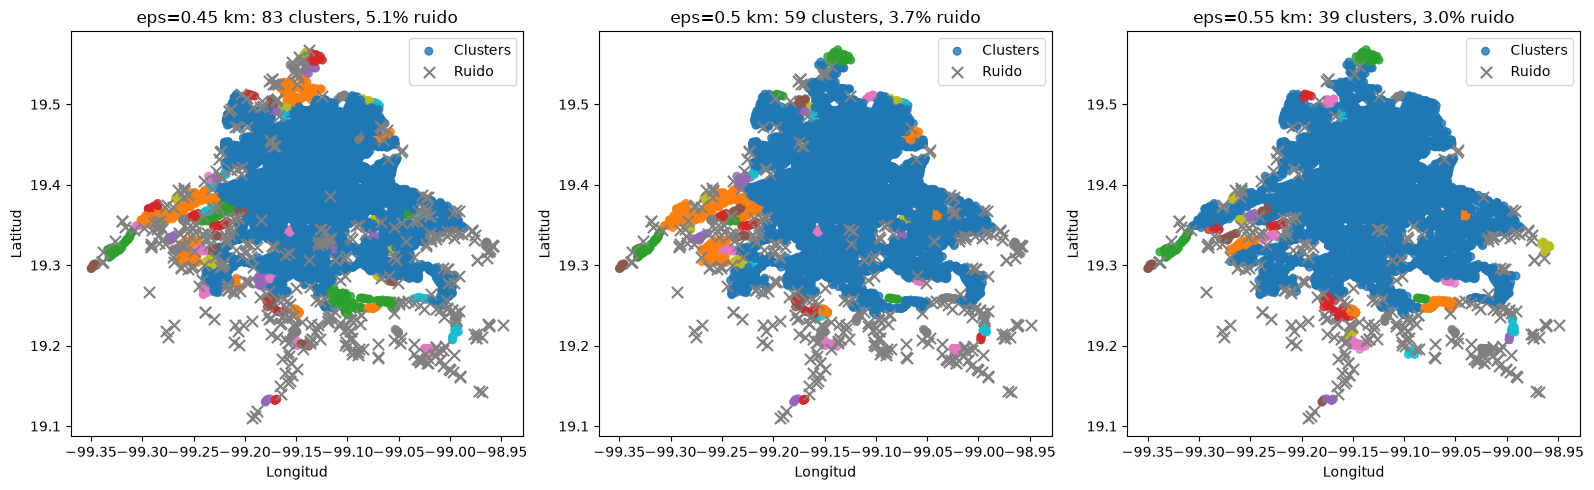

In [34]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, radio_km in zip(axes, [0.45, 0.50, 0.55]):

    etiquetas = dbscan_geo(
        coordenadas_rad,
        eps_km=radio_km,
        min_samples=5
    )


    grupos = len(set(etiquetas) - {-1})


    ruido = np.mean(etiquetas == -1)


    mascara_ruido = etiquetas == -1

    ax.scatter(
        coordenadas[~mascara_ruido, 1],
        coordenadas[~mascara_ruido, 0],
        c=etiquetas[~mascara_ruido],
        cmap="tab10",
        s=30,
        alpha=0.8,
        label="Clusters"
    )

    ax.scatter(
        coordenadas[mascara_ruido, 1],
        coordenadas[mascara_ruido, 0],
        color="gray",
        marker="x",
        s=65,
        label="Ruido"
    )

    ax.set_title(
        f"eps={radio_km} km: {grupos} clusters, "
        f"{ruido:.1%} ruido"
    )

    ax.set_xlabel("Longitud")
    ax.set_ylabel("Latitud")
    ax.legend()

plt.tight_layout()
plt.show()

In [20]:
radios_km = [1.0, 0.50, 0.70]

resultados_tabla = []

for radio_km in radios_km:

    etiquetas = dbscan_geo(
        coordenadas_rad,
        eps_km=radio_km,
        min_samples=5
    )

    identificadores_clusters = set(etiquetas) - {-1}
    numero_clusters = len(identificadores_clusters)

    mascara_ruido = etiquetas == -1
    numero_ruido = np.sum(mascara_ruido)
    proporcion_ruido = np.mean(mascara_ruido)

    tamanos_clusters = (
        pd.Series(etiquetas)
        .loc[lambda serie: serie != -1]
        .value_counts()
    )

    if numero_clusters > 0:
        tamano_minimo = tamanos_clusters.min()
        tamano_medio = tamanos_clusters.mean()
        tamano_mediano = tamanos_clusters.median()
        tamano_maximo = tamanos_clusters.max()
    else:
        tamano_minimo = 0
        tamano_medio = 0
        tamano_mediano = 0
        tamano_maximo = 0

    resultados_tabla.append({
        "Eps (km)": radio_km,
        "Min. muestras": 5,
        "N.º de clústeres": numero_clusters,
        "Tamaño mínimo": tamano_minimo,
        "Tamaño medio": tamano_medio,
        "Tamaño mediano": tamano_mediano,
        "Tamaño máximo": tamano_maximo,
        "N.º de ruido": numero_ruido,
        "Ruido (%)": proporcion_ruido * 100
    })

tabla_comparacion_1 = pd.DataFrame(resultados_tabla)

tabla_comparacion = tabla_comparacion_1.sort_values(
    by="Eps (km)"
).reset_index(drop=True)

tabla_comparacion["Tamaño medio"] = (
    tabla_comparacion["Tamaño medio"].round(2)
)

tabla_comparacion["Tamaño mediano"] = (
    tabla_comparacion["Tamaño mediano"].round(2)
)

tabla_comparacion["Ruido (%)"] = (
    tabla_comparacion["Ruido (%)"].round(2)
)

display(tabla_comparacion_1)

,Eps (km),Min. muestras,N.º de clústeres,Tamaño mínimo,Tamaño medio,Tamaño mediano,Tamaño máximo,N.º de ruido,Ruido (%)
0,1.0,5,14,3,618.071429,9.0,8506,45,0.517360
1,0.5,5,59,3,141.949153,8.0,7438,323,3.713497
2,0.7,5,21,4,407.857143,8.0,8375,133,1.529087


## Combinación 2. min_sample = 3 con eps de 0.45, 0.50, 0.55

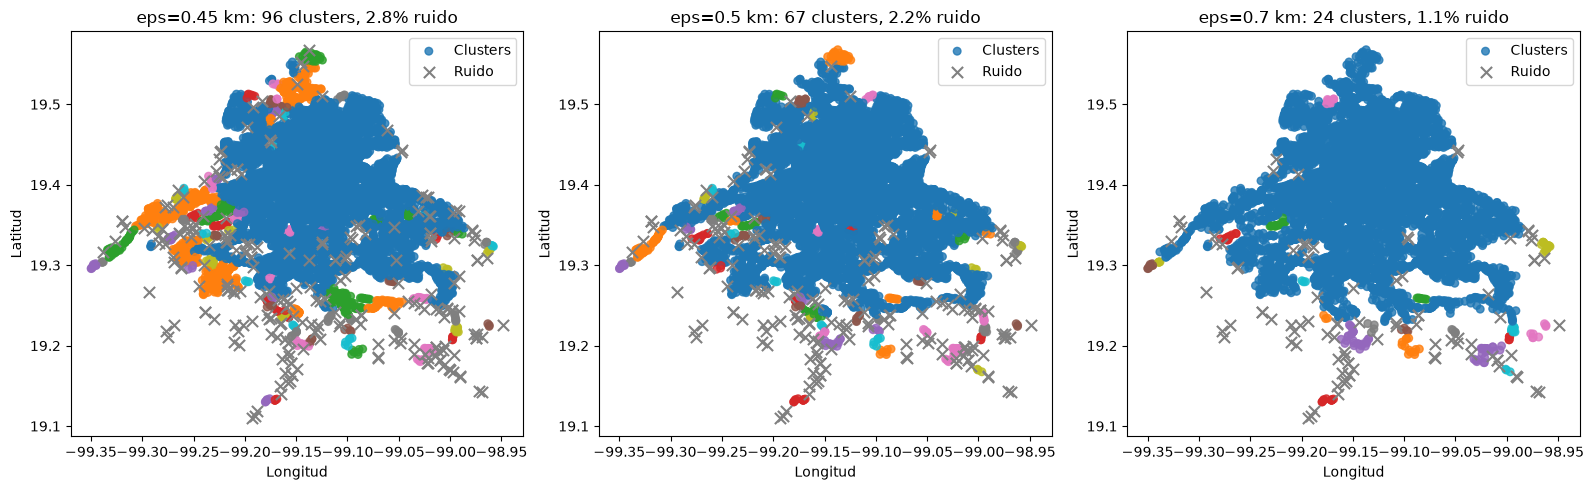

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, radio_km in zip(axes, [0.45, 0.50, 0.70]):

    etiquetas = dbscan_geo(
        coordenadas_rad,
        eps_km=radio_km,
        min_samples=3
    )

    grupos = len(set(etiquetas) - {-1})

    ruido = np.mean(etiquetas == -1)


    mascara_ruido = etiquetas == -1

    ax.scatter(
        coordenadas[~mascara_ruido, 1],
        coordenadas[~mascara_ruido, 0],
        c=etiquetas[~mascara_ruido],
        cmap="tab10",
        s=30,
        alpha=0.8,
        label="Clusters"
    )

    ax.scatter(
        coordenadas[mascara_ruido, 1],
        coordenadas[mascara_ruido, 0],
        color="gray",
        marker="x",
        s=65,
        label="Ruido"
    )

    ax.set_title(
        f"eps={radio_km} km: {grupos} clusters, "
        f"{ruido:.1%} ruido"
    )

    ax.set_xlabel("Longitud")
    ax.set_ylabel("Latitud")
    ax.legend()

plt.tight_layout()
plt.show()

In [21]:
radios_km = [0.45, 0.50, 0.70]

resultados_tabla = []

for radio_km in radios_km:

    etiquetas = dbscan_geo(
        coordenadas_rad,
        eps_km=radio_km,
        min_samples=3
    )

    identificadores_clusters = set(etiquetas) - {-1}
    numero_clusters = len(identificadores_clusters)

    mascara_ruido = etiquetas == -1
    numero_ruido = np.sum(mascara_ruido)
    proporcion_ruido = np.mean(mascara_ruido)

    tamanos_clusters = (
        pd.Series(etiquetas)
        .loc[lambda serie: serie != -1]
        .value_counts()
    )

    if numero_clusters > 0:
        tamano_minimo = tamanos_clusters.min()
        tamano_medio = tamanos_clusters.mean()
        tamano_mediano = tamanos_clusters.median()
        tamano_maximo = tamanos_clusters.max()
    else:
        tamano_minimo = 0
        tamano_medio = 0
        tamano_mediano = 0
        tamano_maximo = 0

    resultados_tabla.append({
        "Eps (km)": radio_km,
        "Min. muestras": 3,
        "N.º de clústeres": numero_clusters,
        "Tamaño mínimo": tamano_minimo,
        "Tamaño medio": tamano_medio,
        "Tamaño mediano": tamano_mediano,
        "Tamaño máximo": tamano_maximo,
        "N.º de ruido": numero_ruido,
        "Ruido (%)": proporcion_ruido * 100
    })

tabla_comparacion_2 = pd.DataFrame(resultados_tabla)

tabla_comparacion = tabla_comparacion_2.sort_values(
    by="Eps (km)"
).reset_index(drop=True)

tabla_comparacion["Tamaño medio"] = (
    tabla_comparacion["Tamaño medio"].round(2)
)

tabla_comparacion["Tamaño mediano"] = (
    tabla_comparacion["Tamaño mediano"].round(2)
)

tabla_comparacion["Ruido (%)"] = (
    tabla_comparacion["Ruido (%)"].round(2)
)

display(tabla_comparacion_2)

,Eps (km),Min. muestras,N.º de clústeres,Tamaño mínimo,Tamaño medio,Tamaño mediano,Tamaño máximo,N.º de ruido,Ruido (%)
0,0.45,3,96,3,88.104167,6.0,7054,240,2.759255
1,0.50,3,67,3,127.014925,5.0,7965,188,2.161416
2,0.70,3,24,3,358.500000,7.5,8405,94,1.080708


## Combinación 3. min_sample = 10 con eps de 0.45, 0.50, 0.55

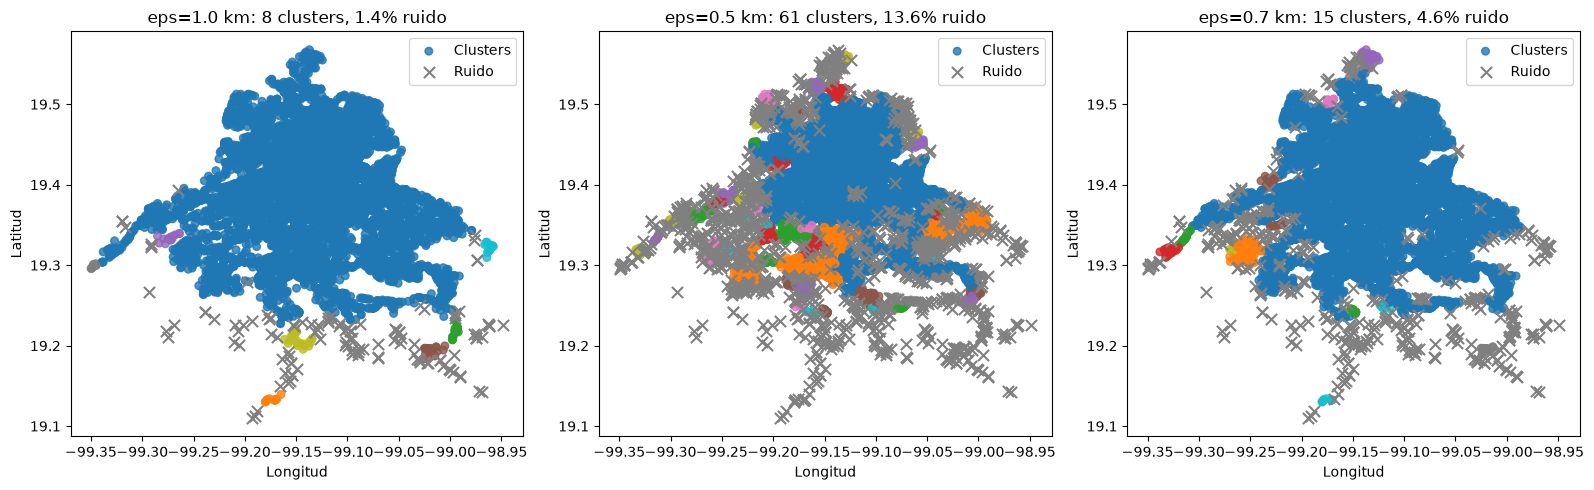

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, radio_km in zip(axes, [1.0, 0.50, 0.70]):

    etiquetas = dbscan_geo(
        coordenadas_rad,
        eps_km=radio_km,
        min_samples=10
    )

    grupos = len(set(etiquetas) - {-1})

    ruido = np.mean(etiquetas == -1)

    mascara_ruido = etiquetas == -1

    ax.scatter(
        coordenadas[~mascara_ruido, 1],
        coordenadas[~mascara_ruido, 0],
        c=etiquetas[~mascara_ruido],
        cmap="tab10",
        s=30,
        alpha=0.8,
        label="Clusters"
    )

    ax.scatter(
        coordenadas[mascara_ruido, 1],
        coordenadas[mascara_ruido, 0],
        color="gray",
        marker="x",
        s=65,
        label="Ruido"
    )

    ax.set_title(
        f"eps={radio_km} km: {grupos} clusters, "
        f"{ruido:.1%} ruido"
    )

    ax.set_xlabel("Longitud")
    ax.set_ylabel("Latitud")
    ax.legend()

plt.tight_layout()
plt.show()

In [35]:
radios_km = [1.0, 0.50, 0.70]

resultados_tabla = []

for radio_km in radios_km:

    etiquetas = dbscan_geo(
        coordenadas_rad,
        eps_km=radio_km,
        min_samples=10
    )

    identificadores_clusters = set(etiquetas) - {-1}
    numero_clusters = len(identificadores_clusters)

    mascara_ruido = etiquetas == -1
    numero_ruido = np.sum(mascara_ruido)
    proporcion_ruido = np.mean(mascara_ruido)

    tamanos_clusters = (
        pd.Series(etiquetas)
        .loc[lambda serie: serie != -1]
        .value_counts()
    )

    if numero_clusters > 0:
        tamano_minimo = tamanos_clusters.min()
        tamano_medio = tamanos_clusters.mean()
        tamano_mediano = tamanos_clusters.median()
        tamano_maximo = tamanos_clusters.max()
    else:
        tamano_minimo = 0
        tamano_medio = 0
        tamano_mediano = 0
        tamano_maximo = 0

    resultados_tabla.append({
        "Eps (km)": radio_km,
        "Min. muestras": 10,
        "N.º de clústeres": numero_clusters,
        "Tamaño mínimo": tamano_minimo,
        "Tamaño medio": tamano_medio,
        "Tamaño mediano": tamano_mediano,
        "Tamaño máximo": tamano_maximo,
        "N.º de ruido": numero_ruido,
        "Ruido (%)": proporcion_ruido * 100
    })

tabla_comparacion_3 = pd.DataFrame(resultados_tabla)

tabla_comparacion = tabla_comparacion_3.sort_values(
    by="Eps (km)"
).reset_index(drop=True)

tabla_comparacion["Tamaño medio"] = (
    tabla_comparacion["Tamaño medio"].round(2)
)

tabla_comparacion["Tamaño mediano"] = (
    tabla_comparacion["Tamaño mediano"].round(2)
)

tabla_comparacion["Ruido (%)"] = (
    tabla_comparacion["Ruido (%)"].round(2)
)

display(tabla_comparacion_3)

,Eps (km),Min. muestras,N.º de clústeres,Tamaño mínimo,Tamaño medio,Tamaño mediano,Tamaño máximo,N.º de ruido,Ruido (%)
0,1.0,10,8,8,1072.000000,16.0,8467,122,1.402621
1,0.5,10,61,6,123.229508,16.0,4903,1181,13.577834
2,0.7,10,15,5,553.000000,15.0,8003,403,4.633249


In [37]:
tabla_comparacion_final = pd.concat(
    [
        tabla_comparacion_1,
        tabla_comparacion_2,
        tabla_comparacion_3
    ],
    ignore_index=True
)

display(tabla_comparacion_final)

,Eps (km),Min. muestras,N.º de clústeres,Tamaño mínimo,Tamaño medio,Tamaño mediano,Tamaño máximo,N.º de ruido,Ruido (%)
0,1.00,5,14,3,618.071429,9.0,8506,45,0.517360
1,0.50,5,59,3,141.949153,8.0,7438,323,3.713497
2,0.70,5,21,4,407.857143,8.0,8375,133,1.529087
3,0.45,3,96,3,88.104167,6.0,7054,240,2.759255
4,0.50,3,67,3,127.014925,5.0,7965,188,2.161416
5,0.70,3,24,3,358.500000,7.5,8405,94,1.080708
6,1.00,10,8,8,1072.000000,16.0,8467,122,1.402621
7,0.50,10,61,6,123.229508,16.0,4903,1181,13.577834
8,0.70,10,15,5,553.000000,15.0,8003,403,4.633249


### Resultados. 
Con la información anterior, se tomo la decisión de escojer al cluster de eps 0.50 y min__muestra de 5, ya que este cuenta con la mejor representación del modelo. Además de contar con un tamaño de ruido razobnable. A pesar de lo anterior, el DBSCAN escogido cuenta con 59 clusters, lo que genera una gran saturación y no permite una correcta interpretación en la concentración de riesgos de falsas alarmas. Derivado de lo anterior, se llega a la conclusión que la técnica DBSCAN no es la correcta para esta base de datos.  

# Parte 4. Interpretación

In [38]:
muestra["cluster_dbscan"] = dbscan_geo(
    coordenadas_rad,
    eps_km=0.50,
    min_samples=5
)

muestra["ubicacion_cluster"] = np.where(
    muestra["cluster_dbscan"] == -1,
    "Fuera de los clústeres",
    "Dentro de los clústeres"
)

muestra[
    ["codigo_cierre", "cluster_dbscan", "ubicacion_cluster"]
].head()

,codigo_cierre,cluster_dbscan,ubicacion_cluster
82268,D,0,Dentro de los clústeres
92054,A,0,Dentro de los clústeres
116478,D,0,Dentro de los clústeres
16191,A,0,Dentro de los clústeres
9612,A,0,Dentro de los clústeres


In [26]:
tabla_conteos = pd.crosstab(
    muestra["ubicacion_cluster"],
    muestra["codigo_cierre"]
)

display(tabla_conteos)

codigo_cierre,A,D,F,I
ubicacion_cluster,,,,
Dentro de los clústeres,3070,3565,1688,52
Fuera de los clústeres,103,133,79,8


In [27]:
tabla_proporciones = pd.crosstab(
    muestra["ubicacion_cluster"],
    muestra["codigo_cierre"],
    normalize="index"
) * 100

tabla_proporciones = tabla_proporciones.round(2)

display(tabla_proporciones)

codigo_cierre,A,D,F,I
ubicacion_cluster,,,,
Dentro de los clústeres,36.66,42.57,20.16,0.62
Fuera de los clústeres,31.89,41.18,24.46,2.48


In [28]:
tabla_resultados = pd.concat(
    [
        tabla_conteos,
        tabla_proporciones
    ],
    keys=["Conteos", "Proporciones (%)"]
)

display(tabla_resultados)

codigo_cierre                                   A        D        F      I
                 ubicacion_cluster                                        
Conteos          Dentro de los clústeres  3070.00  3565.00  1688.00  52.00
                 Fuera de los clústeres    103.00   133.00    79.00   8.00
Proporciones (%) Dentro de los clústeres    36.66    42.57    20.16   0.62
                 Fuera de los clústeres     31.89    41.18    24.46   2.48

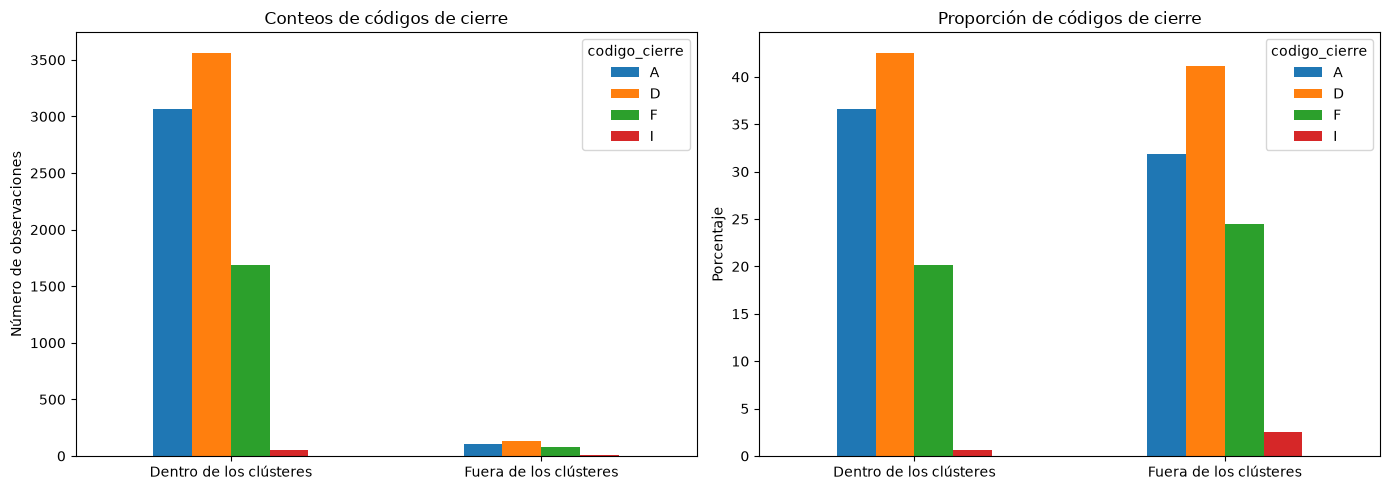

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

tabla_conteos.plot(
    kind="bar",
    ax=axes[0]
)

axes[0].set_title("Conteos de códigos de cierre")
axes[0].set_xlabel("")
axes[0].set_ylabel("Número de observaciones")
axes[0].tick_params(axis="x", rotation=0)

tabla_proporciones.plot(
    kind="bar",
    ax=axes[1]
)

axes[1].set_title("Proporción de códigos de cierre")
axes[1].set_xlabel("")
axes[1].set_ylabel("Porcentaje")
axes[1].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

Resultados: El modelo elegido cuenta con una gran captación de conteos de código cierre en los clusters creados con la técnica de DBSCAN. De estos códigos, los códigos de duplicados son los que cuentan con una mayor proporción, esto sigue acorde a la información natural de la base y a lo ocurrido en el notebook de nb03_supervisado_c5.

# Parte 5. Limitaciones. 

La técnica BDSCAN no se considera adecuada para esta base de datos, ya que al contar con una gran cantidad de observaciones y una distancia "geográfica limitada", dificulta el manejo de los parámetros generando que se creen pocos clusters muy saturadas, provocando que el análisis sea ineficiente para explicar los eventos.

Por otra parte, la concentración de reportes puede aumentar con esta técnica en términos absolutos debido a la concentración de reportes dentro de los clusters, no obstante, en términos de proporción la tasa puede bajar por la misma razón. 

## Pregunta para discutir:

### ¿Qué información aporta DBSCAN que no se observa directamente en los resultados del supervisado?
La técnica DBSCAN identifica y agrupa zonas geográficas con alta concentración de reportes, lo que permite identificar patrones y cómo se distribuyen los códigos.

### ¿Qué limitaciones del aprendizaje supervisado motiva explorar, y cuáles no resuelve DBSCAN?
